# 03 - Exploratory Data Analysis

**Questions**

1. How large is the business and how is revenue distributed across stores?
2. What is the weekly and annual rhythm of sales?
3. Do promotions, holidays and competition proximity coincide with different sales levels?
4. Which stores are volatile and deserve operational attention?

Every chart in this notebook is generated by `src/eda.py`; the numbers are read from `outputs/metrics/eda_summary.json`, so the narrative cannot drift from the data.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


## 1. Headline numbers

In [2]:
summary = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "eda_summary.json").read_text())
overview = pd.Series(summary["overview"]).to_frame("value")
display(overview)

print(f"Top 10% of stores generate {summary['overview']['sales_share_top10pct_stores']:.1%} of chain revenue.")
print(f"Average basket (sales / customers) is {summary['overview']['avg_basket']:.2f} PLN.")

,value
date_min,2013-01-01
date_max,2015-07-31
rows,1017209
stores,1115
total_sales,5873180623.0
total_customers,644041755.0
avg_daily_sales_open,6955.514291
median_daily_sales_open,6369.0
avg_daily_sales_all_rows,5773.818972
avg_customers_open,762.728395


Top 10% of stores generate 17.8% of chain revenue.
Average basket (sales / customers) is 9.12 PLN.


**Interpretation.** The dataset contains 5.87 bn PLN of turnover over 2.5 years. Average daily sales on open days are 6,956 PLN, but the median is 6,369 PLN: the mean is pulled up by a small group of very large stores. The top decile of stores accounts for about 18% of revenue, so a single forecasting model must handle very different store scales.

## 2. Trend and weekly rhythm

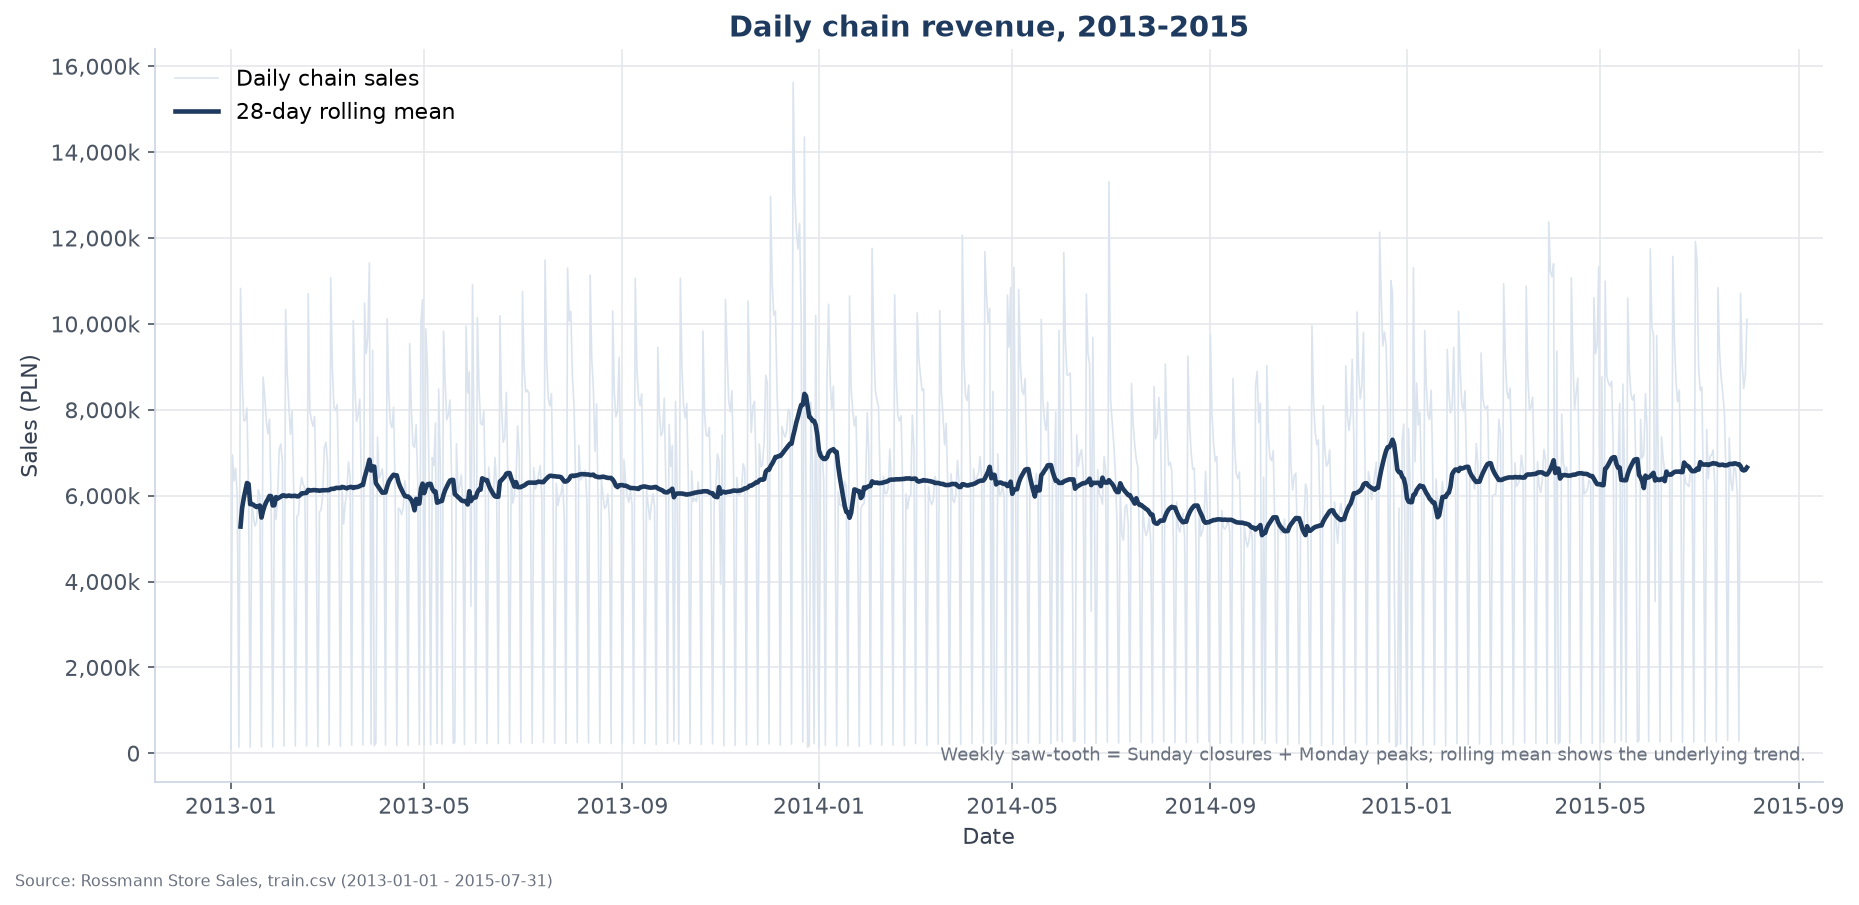

In [3]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig01_daily_sales_trend.png"), width=950))

**Variables:** daily chain sales (sum over stores) and its 28-day rolling mean.

**Interpretation.** The saw-tooth is weekly seasonality: most stores are closed on Sunday, Monday is the strongest day. The rolling mean shows a flat-to-slightly-growing trend in 2013, a dip in late 2014, and a recovery in 2015. There is no explosive growth, which is consistent with a mature store network.

**Business meaning.** Workforce and replenishment planning should follow the weekly cycle, not the daily noise. Annual planning should use the rolling trend, because single weeks are dominated by calendar effects.

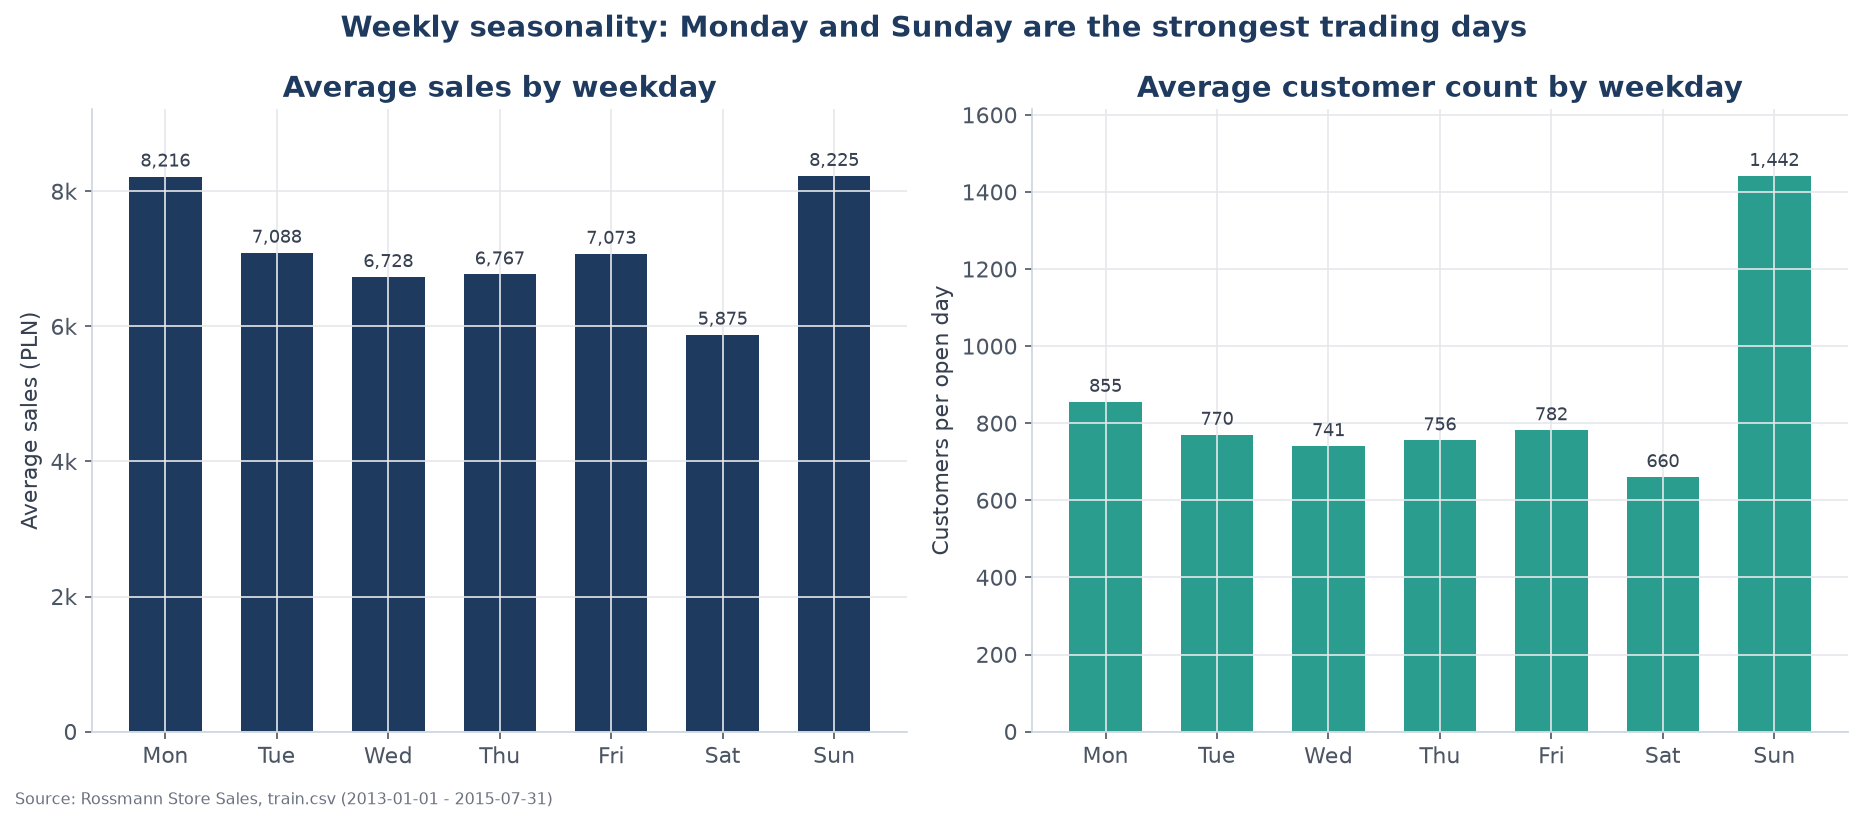

In [4]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig02_weekday_seasonality.png"), width=950))

**Interpretation.** Monday and Sunday have the highest average sales per open store-day. Sunday is high because only a subset of stores opens, and those tend to be high-traffic locations. Saturday is the weakest weekday. Customer counts follow the same pattern, so the weekday effect is traffic-driven rather than basket-driven.

**Business meaning.** Staffing should peak on Monday; Saturday needs fewer staff per store but may need different assortment availability. Any forecast that ignores the weekday will be wrong by up to ~40% on individual days.

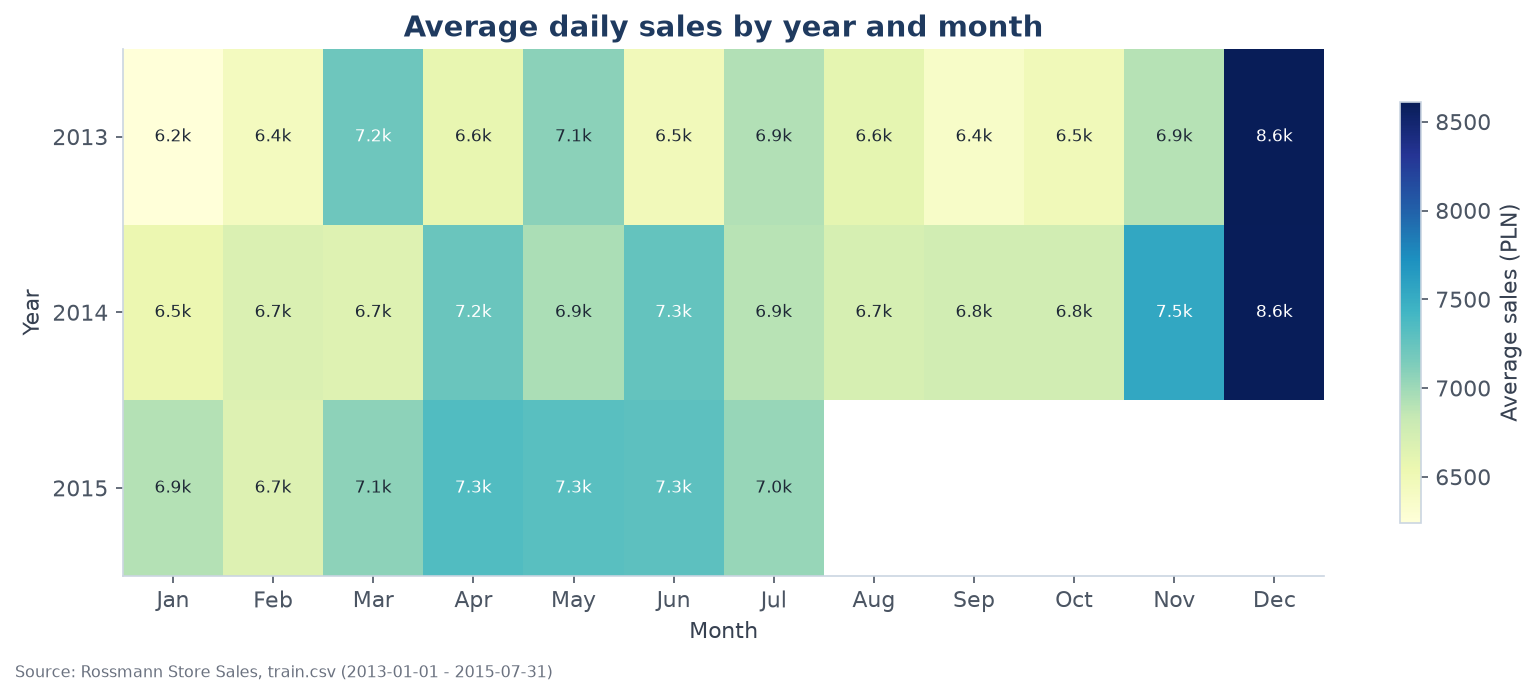

In [5]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig03_monthly_heatmap.png"), width=950))

**Interpretation.** The heatmap shows a summer peak (June-August) and a post-Christmas dip. December is strong but volatile. 2015 is generally above 2013-2014 for the same months, which is the level shift that later complicates holdout forecasting.

**Caution.** With only 30 months of data, the "annual seasonality" estimate is based on two summer seasons. It is a description, not a robust seasonal model.

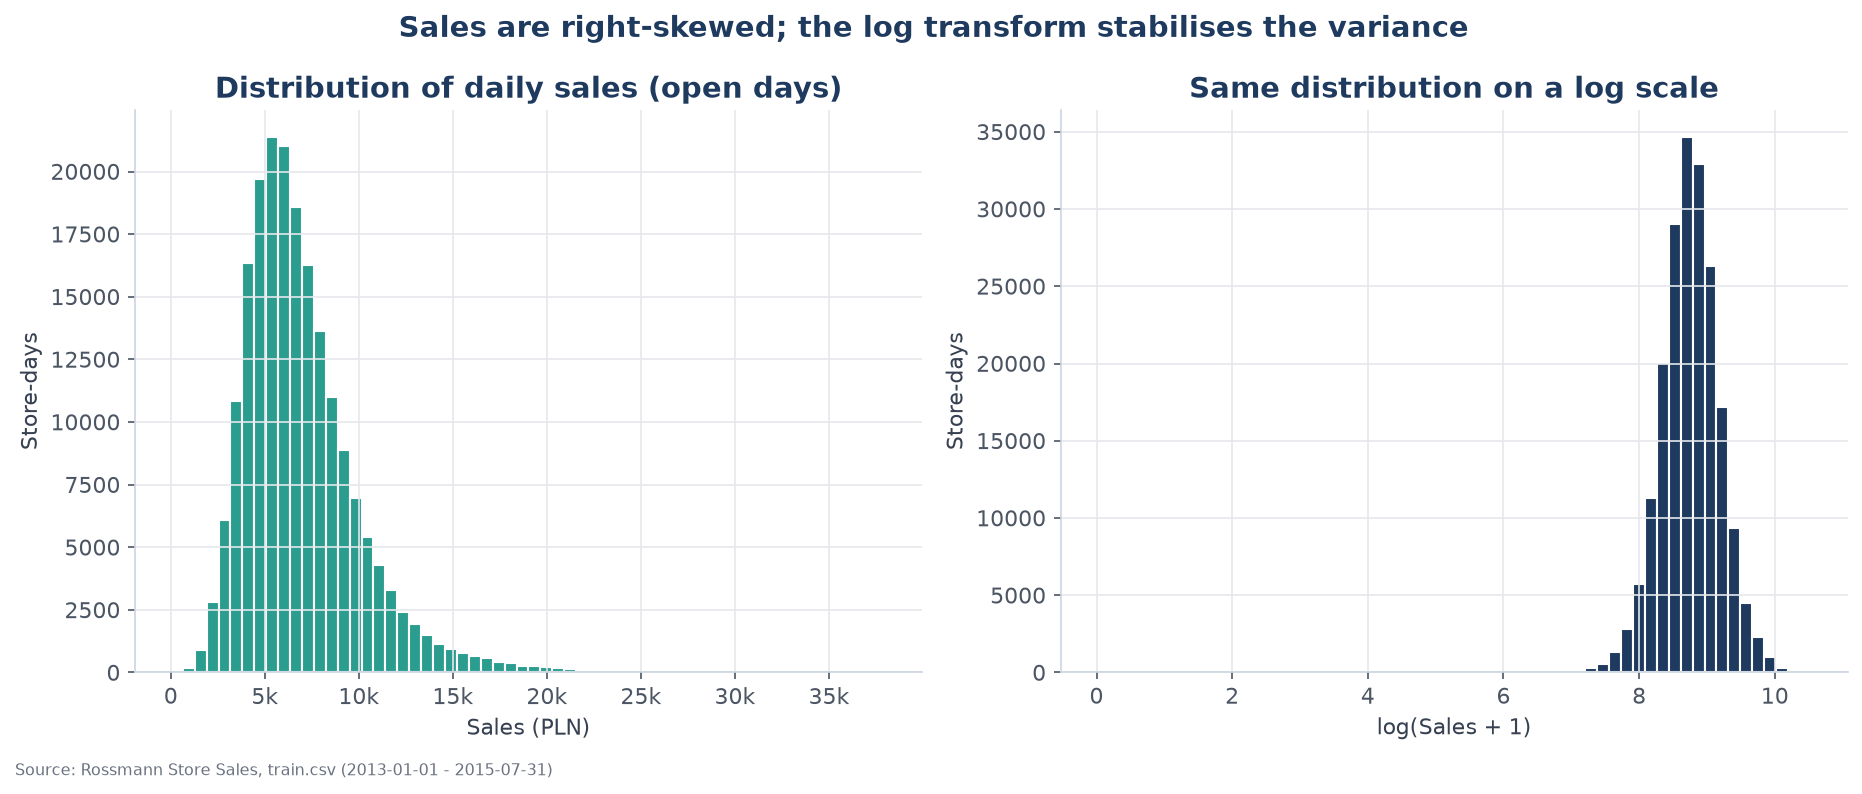

In [6]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig04_sales_distribution.png"), width=950))

**Interpretation.** Daily sales are strongly right-skewed (median 6,369 vs mean 6,956, maximum above 40,000). The log scale is close to symmetric, which motivates modelling `log1p(Sales)` and reporting percentage errors. It also explains why RMSPE is a natural competition metric: it weights a 10% error on a small store the same as a 10% error on a large one.

## 3. Stores and volatility

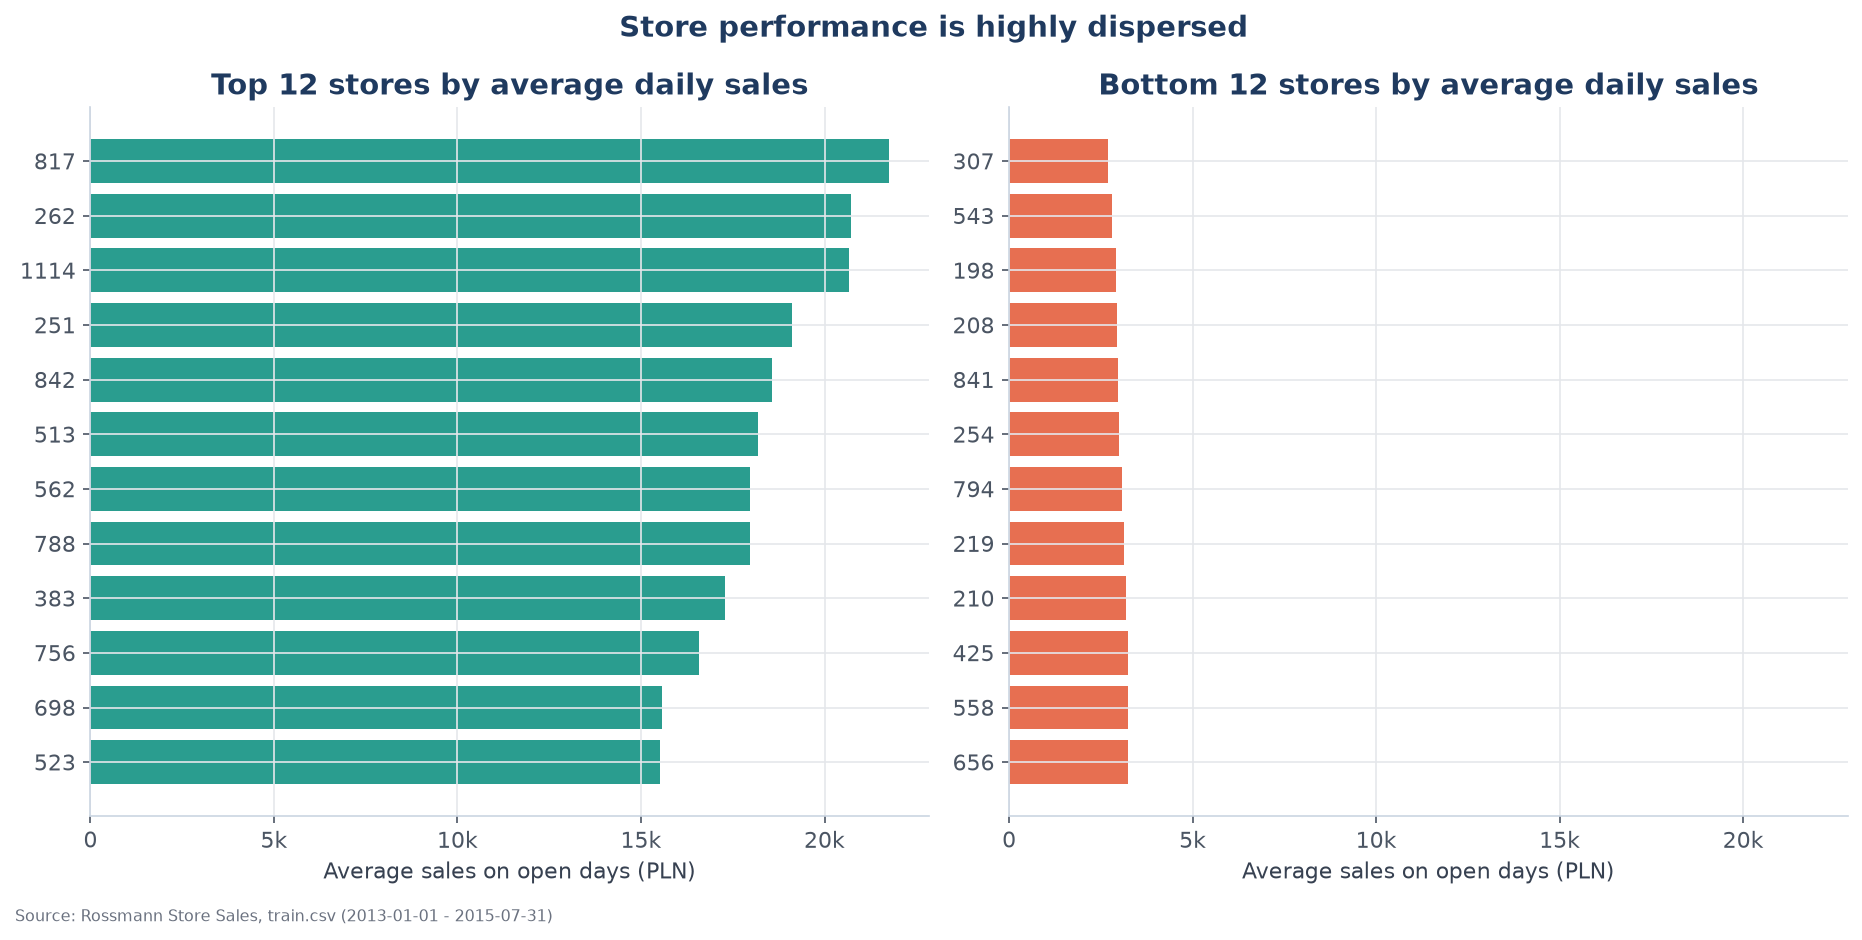

In [7]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig05_store_ranking.png"), width=950))

**Interpretation.** The best store averages more than 22,000 PLN per open day; the weakest averages around 2,000 PLN. The spread is an order of magnitude, so store-level features (or store-level history) are essential. A single global average would be useless for operational planning.

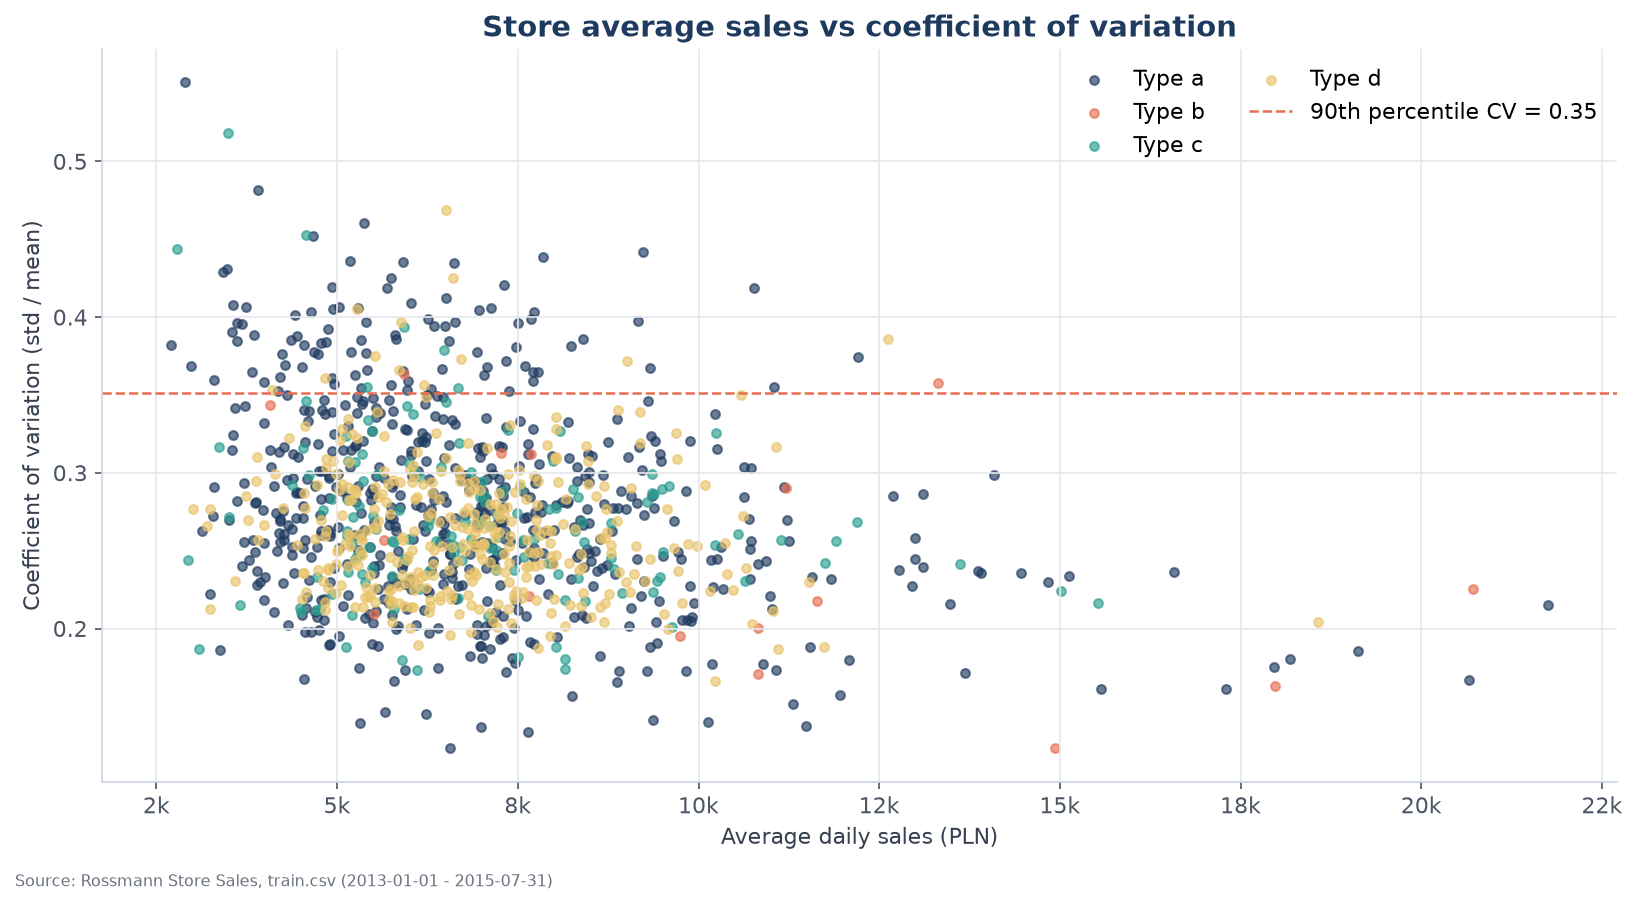

In [8]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig06_store_volatility.png"), width=950))

**Variables:** x = average daily sales, y = coefficient of variation (std / mean) on open days; colour = store type.

**Interpretation.** Volatility is not strongly related to store size. The 90th percentile of CV is around 0.3, and a group of stores is markedly more volatile. These are candidates for closer monitoring, buffer stock and manual review of forecasts.

**Business meaning.** High-CV stores are where forecast errors translate most directly into stock-outs or waste. They deserve a wider safety stock and more frequent re-forecasting.

## 4. Promotions, holidays and competition

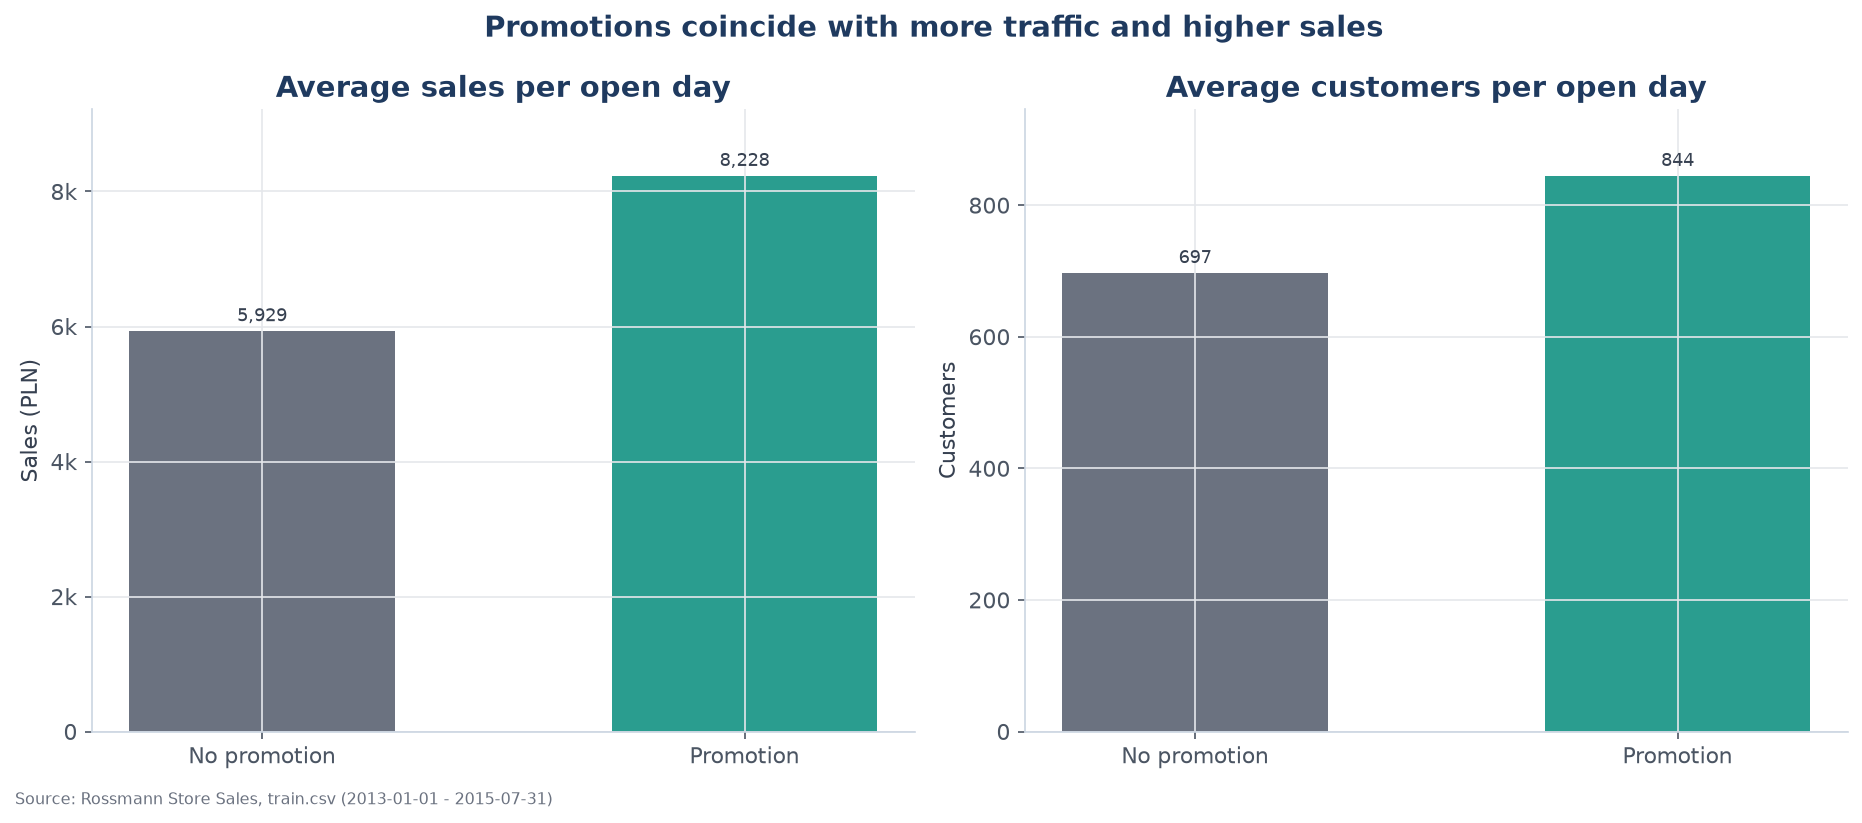

In [9]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig07_promo_effect.png"), width=950))

In [10]:
promo = pd.DataFrame(summary["promo"])
promo["uplift_vs_no_promo_pct"] = (promo["avg_sales"] / promo.loc[promo.Promo == 0, "avg_sales"].iloc[0] - 1) * 100
display(promo)

test = summary["tests"]["promo_paired_t"]
print(f"Paired store-level test: mean uplift {test['mean_uplift']:.0f} PLN, "
      f"median {test['median_uplift']:.0f} PLN, {test['pct_stores_positive']:.1%} of stores positive, "
      f"Cohen's dz = {test['cohens_dz']:.2f}, p = {test['p_value']:.2e}")

,Promo,avg_sales,avg_customers,days,avg_basket,uplift_vs_no_promo_pct
0,0,5929.408,696.857,467496,8.509,0.0000
1,1,8228.281,844.434,376896,9.744,38.7707


Paired store-level test: mean uplift 2299 PLN, median 2193 PLN, 99.9% of stores positive, Cohen's dz = 2.25, p = 0.00e+00


**Interpretation.** Promotion days show roughly 39% higher average sales and 21% more customers. The effect is present in the overwhelming majority of stores (paired test), not driven by a few large locations. The basket value is also higher, so promotions attract both more traffic and larger baskets.

**Causal caution.** Promotions are scheduled by the retailer, not randomly assigned. They may be placed in weeks that were already expected to be strong, and the comparison ignores the post-promotion dip. This is a descriptive association; a causal estimate would require a controlled experiment or a difference-in-differences design with exogenous promotion timing.

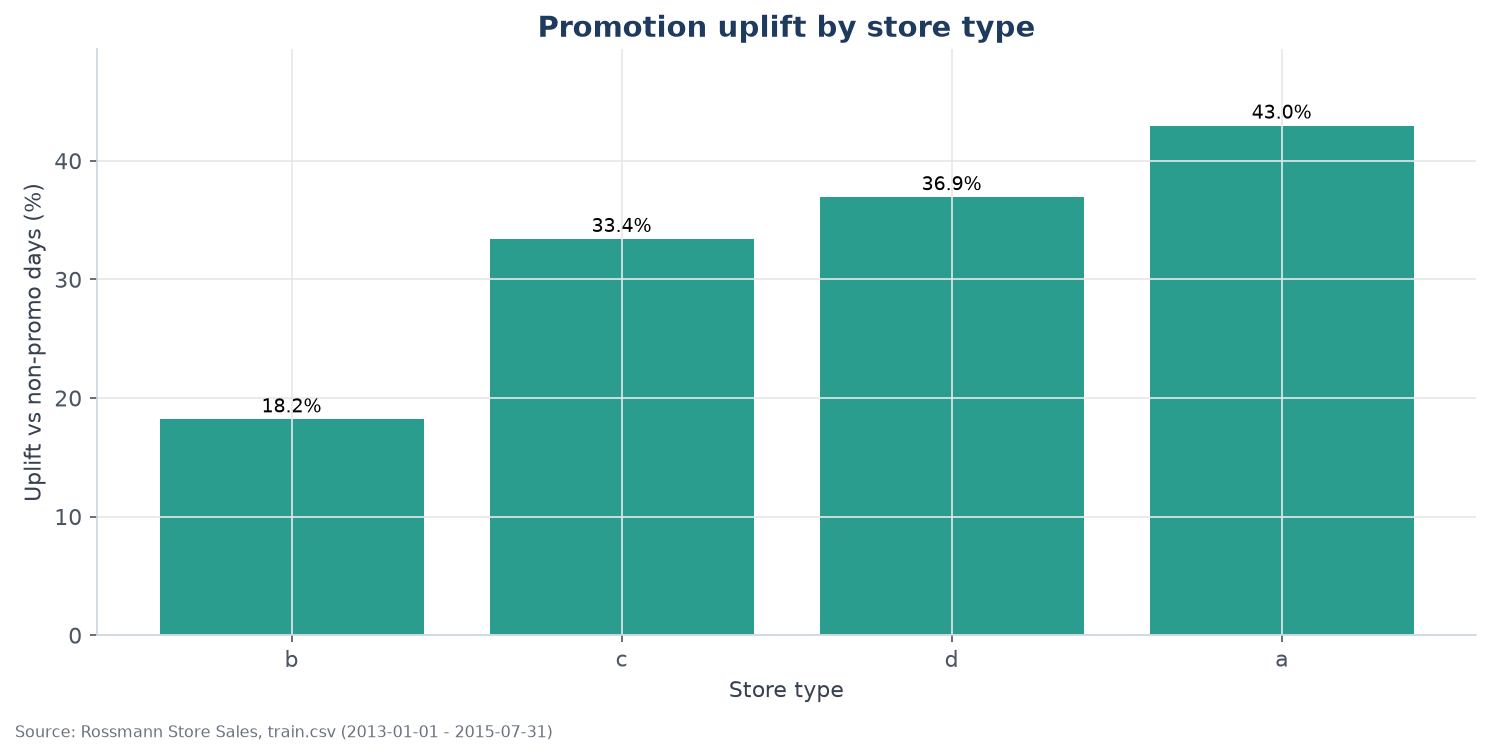

In [11]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig08_promo_uplift_by_type.png"), width=950))

**Interpretation.** All store formats respond positively to promotions, but the magnitude differs. Type b stores (the smallest group, 17 stores) show the largest relative uplift; type a stores show the smallest. The confidence interval is wide for type b because of the small store count.

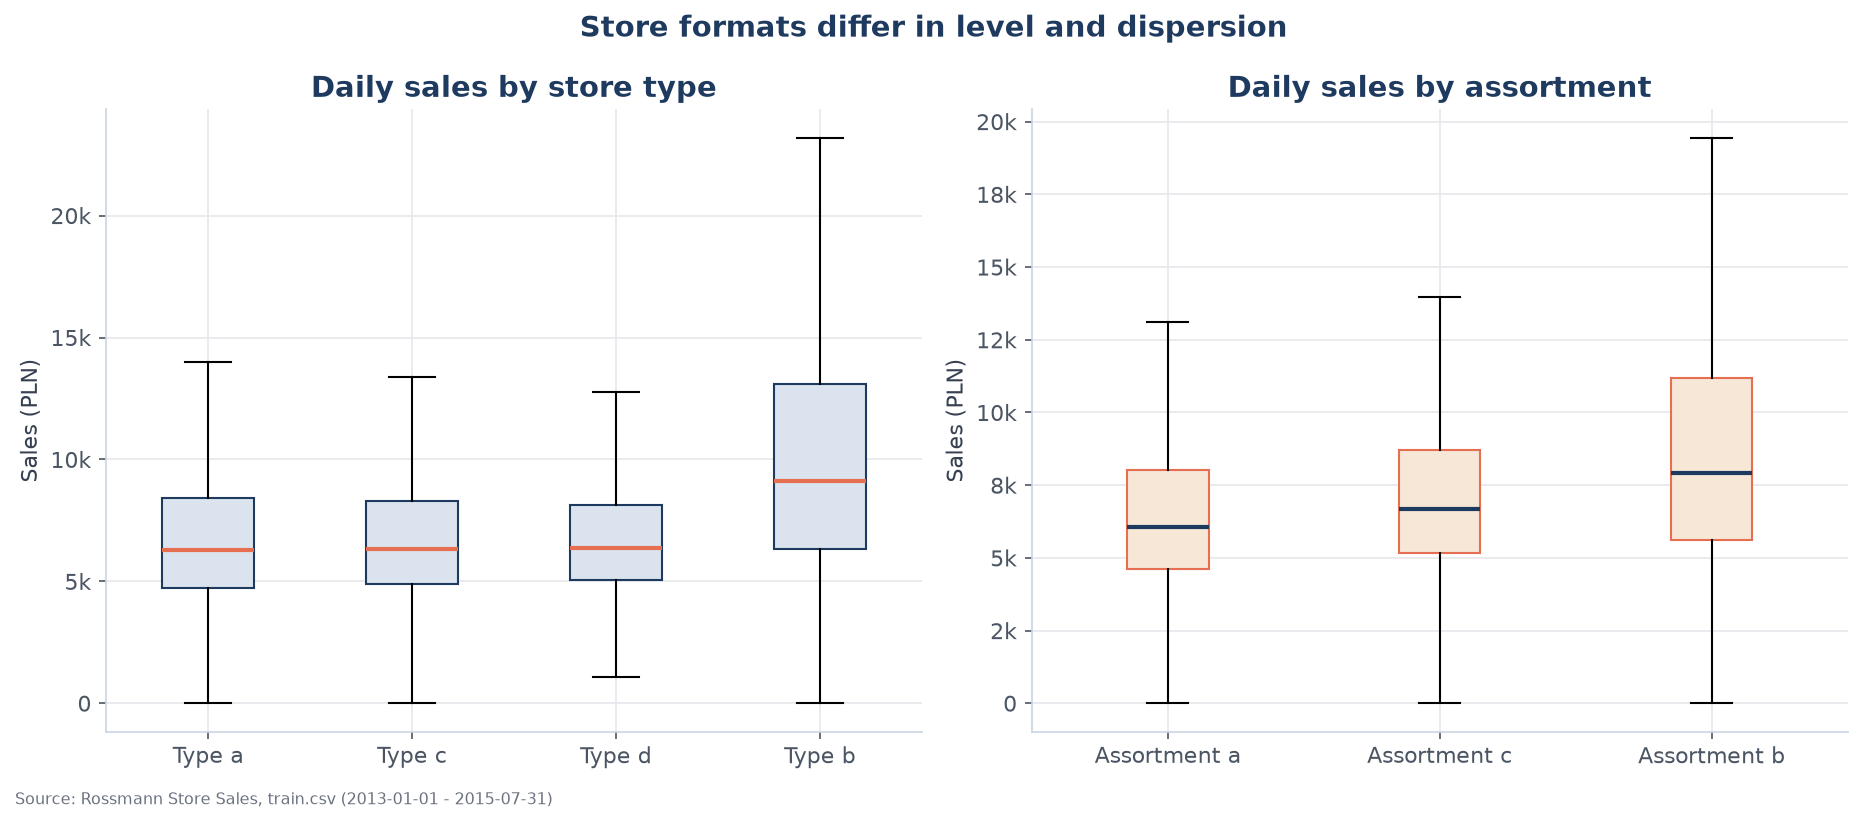

In [12]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig09_store_type_assortment.png"), width=950))

In [13]:
display(pd.DataFrame(summary["store_type"]))
display(pd.DataFrame(summary["assortment"]))
display(pd.DataFrame(summary["holiday"]))

,StoreType,avg_sales,avg_customers,days,avg_basket
0,a,6925.168,795.361,457077,8.707
1,b,10231.408,2021.822,15563,5.060
2,c,6932.513,815.466,112978,8.501
3,d,6822.142,606.340,258774,11.251


,Assortment,avg_sales,days
0,a,6621.017,444909
1,b,8639.346,8212
2,c,7300.526,391271


,StateHoliday,avg_sales,avg_customers,days
0,0,6953.515,762.077,843482
1,a,8487.471,1279.173,694
2,b,9887.890,1686.890,145
3,c,9743.746,1569.225,71


**Interpretation.** Store type b has the highest average sales per open day despite having only 17 stores, while type a is the largest group. Assortment c stores are slightly stronger than assortment a. Differences between formats are statistically significant (Kruskal-Wallis p < 1e-100), but the practical lesson is that store format must be a feature.

Holiday effects are heterogeneous: public holidays (`a`) and Easter (`b`) differ from regular days, while Christmas (`c`) is represented by very few open store-days because most stores close. A model should not learn a strong "Christmas effect" from a handful of observations.

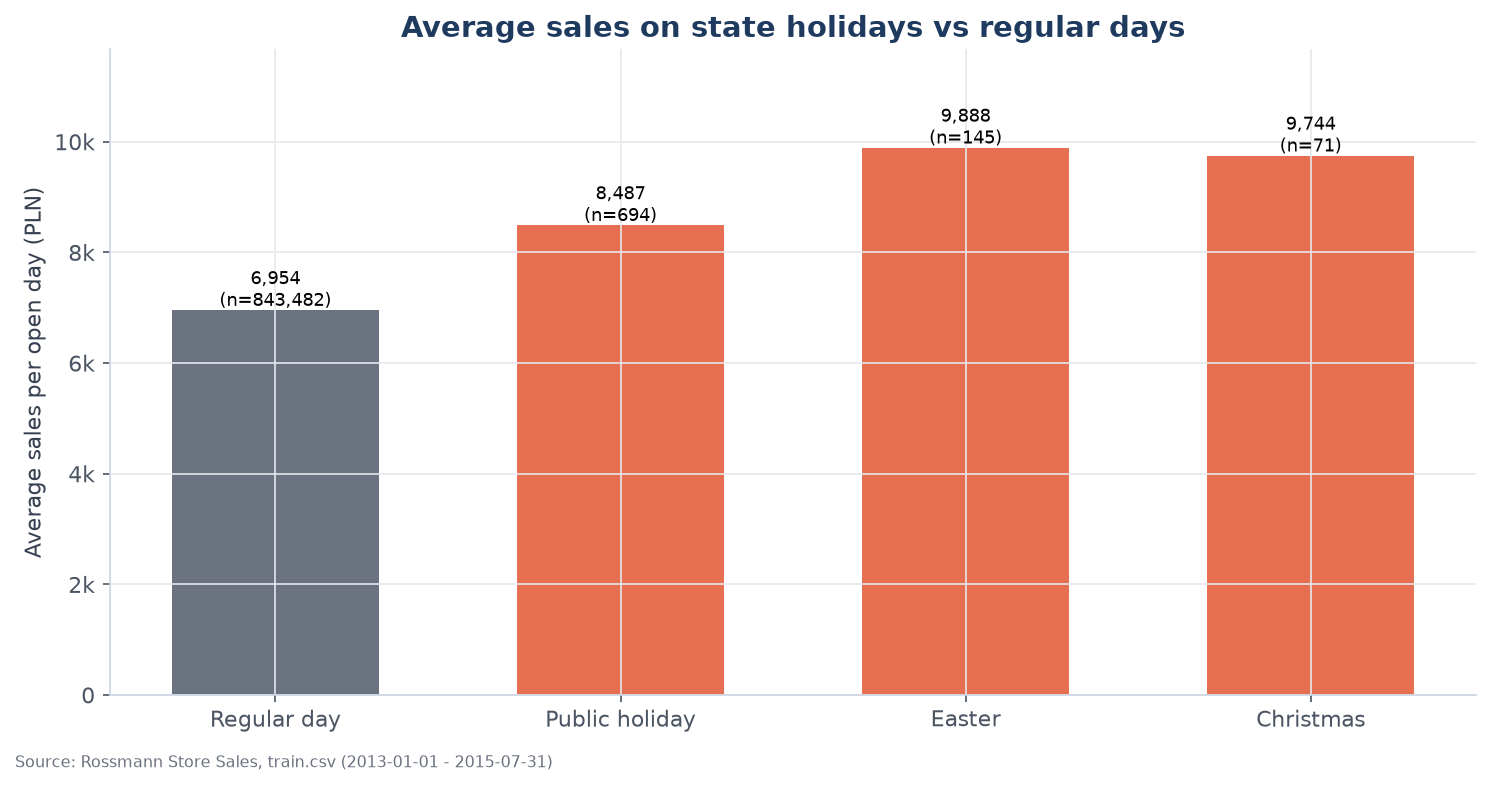

In [14]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig10_holiday_effect.png"), width=950))

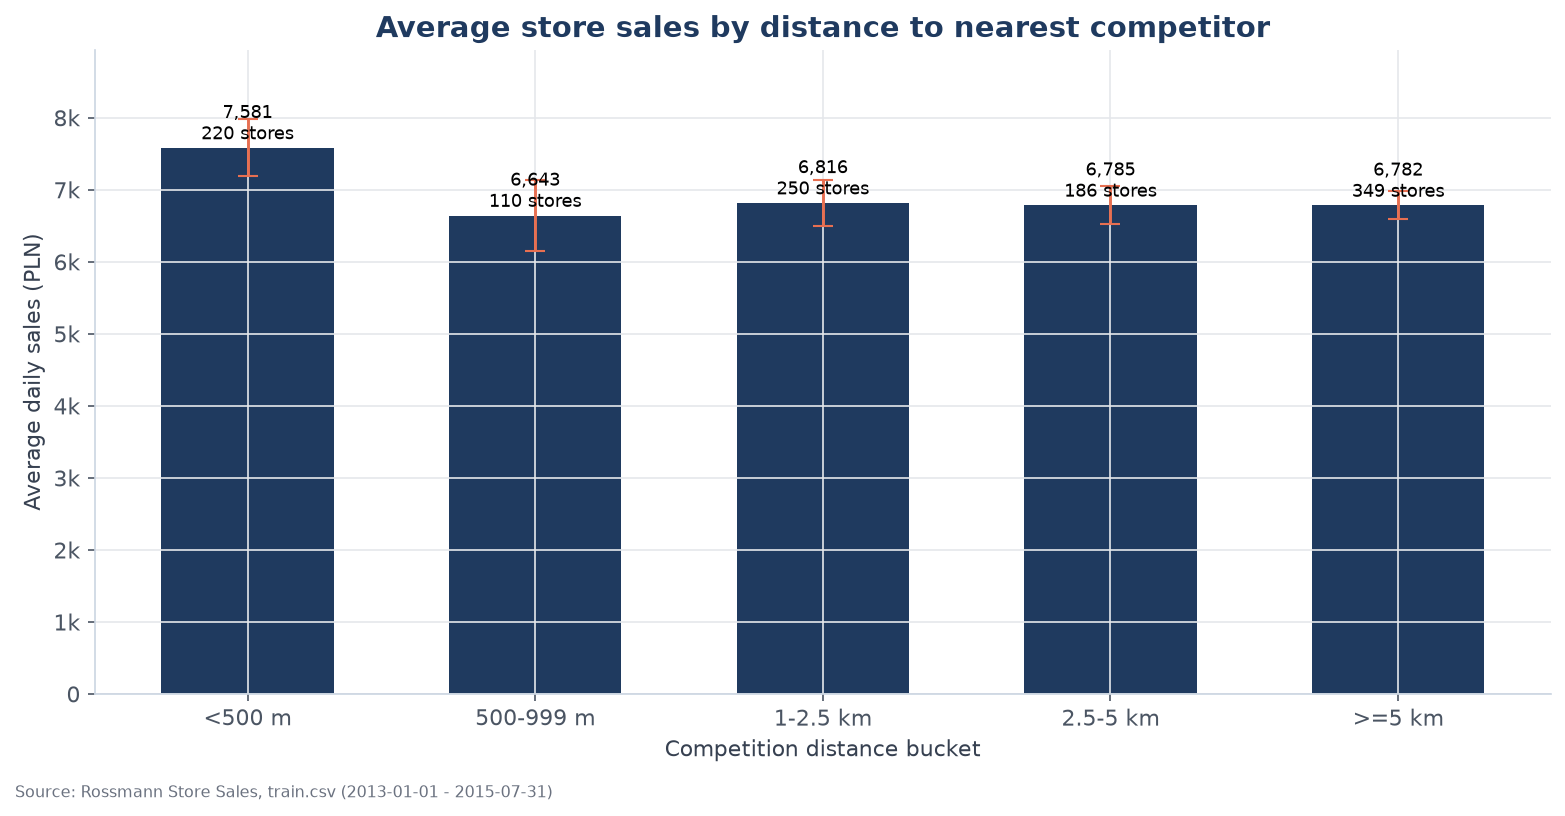

In [15]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig11_competition_distance.png"), width=950))

**Variables:** stores binned by distance to the nearest competitor; bars show average daily sales with 95% confidence intervals.

**Interpretation.** Stores with a competitor within 500 m have higher average sales than stores further away, which sounds counter-intuitive. It is a location effect: dense city centres attract both competitors and high footfall. The Spearman correlation across stores is negative but weak, and it is confounded by store type and location. The exact coefficient is printed in the code cell below. The chart is therefore a description, not evidence that proximity to competitors raises sales.

**Business meaning.** Competition distance should enter the model as a control, not as a lever. Opening a store closer to a competitor is not a strategy implied by this chart.

In [16]:
rho = summary["tests"]["competition_spearman"]
print(f"Spearman rho (competition distance vs store average sales): {rho['rho']:.3f}, p = {rho['p_value']:.3f}, n = {rho['n_stores']} stores")

Spearman rho (competition distance vs store average sales): -0.028, p = 0.353, n = 1115 stores


## 5. Customers and correlation structure

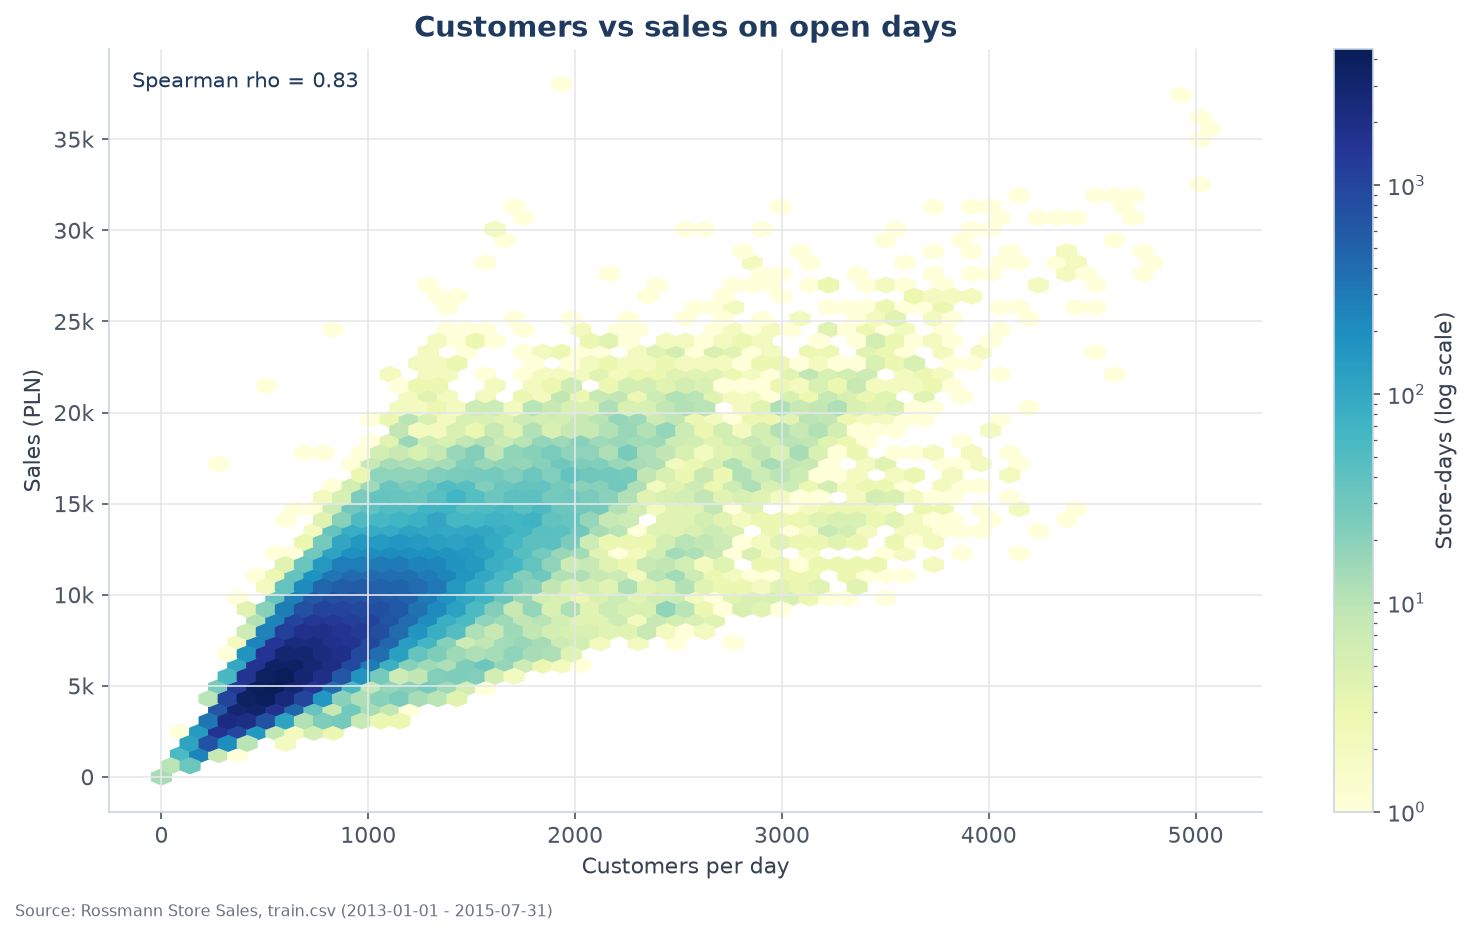

In [17]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig12_customers_vs_sales.png"), width=950))

**Interpretation.** Customers and sales are almost perfectly rank-correlated (rho > 0.9). Traffic is the main driver of revenue; basket size varies much less. This is why `Customers` would be an extremely strong feature - and why it cannot be used for future days: it is unknown at forecast time. Only lagged customer statistics are legitimate, and they are used as frozen origin features.

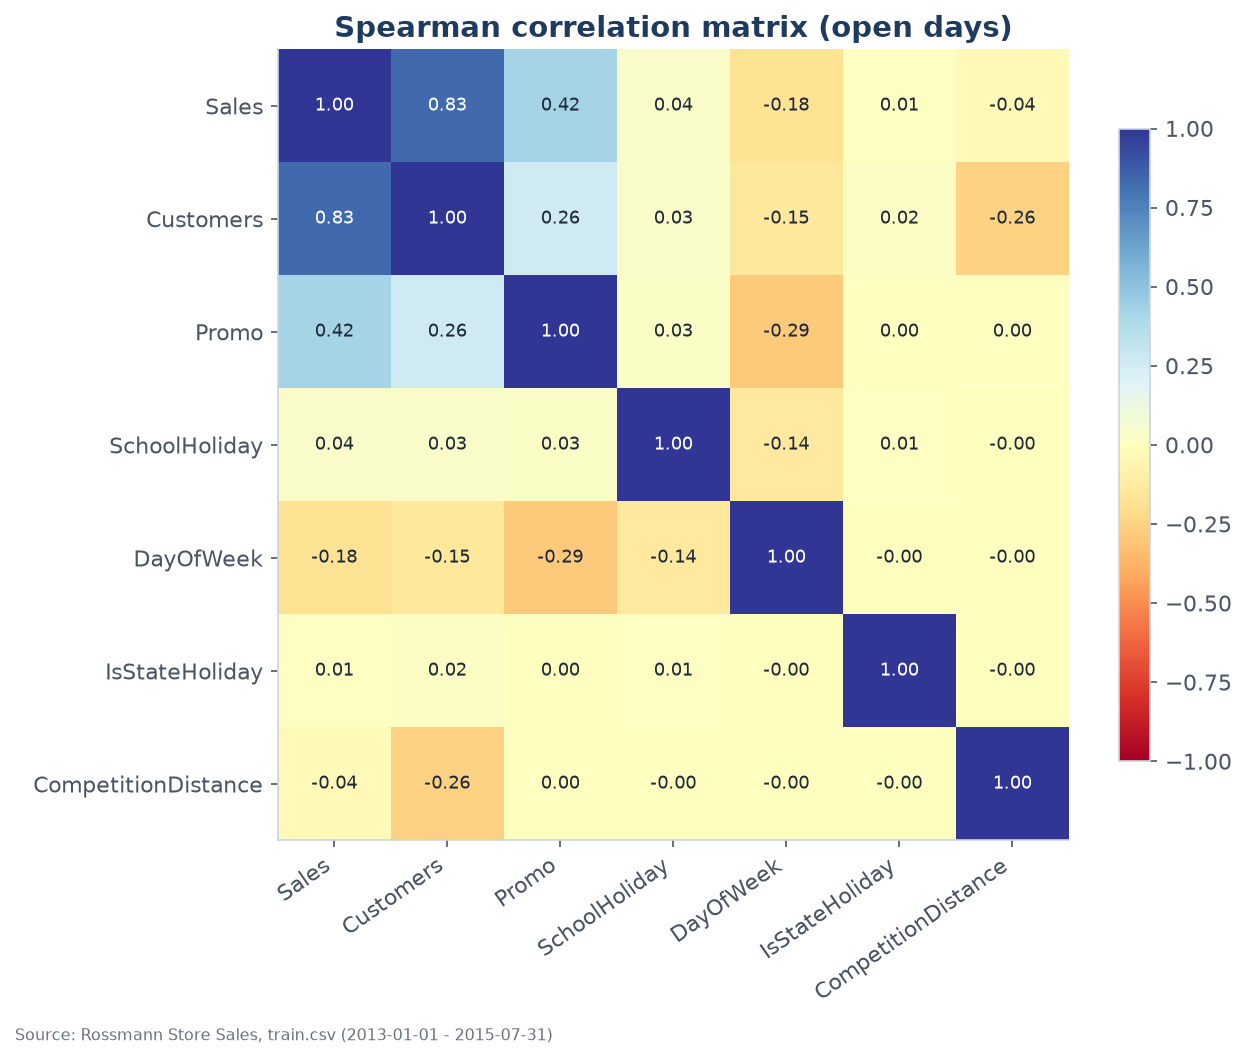

In [18]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig13_correlation_matrix.png"), width=950))

**Caution.** Correlations on pooled store-days mix between-store and within-store variation. A negative correlation between `Promo` and `DayOfWeek` may simply reflect the promotion calendar, not customer behaviour. The matrix is useful for screening, not for causal claims.

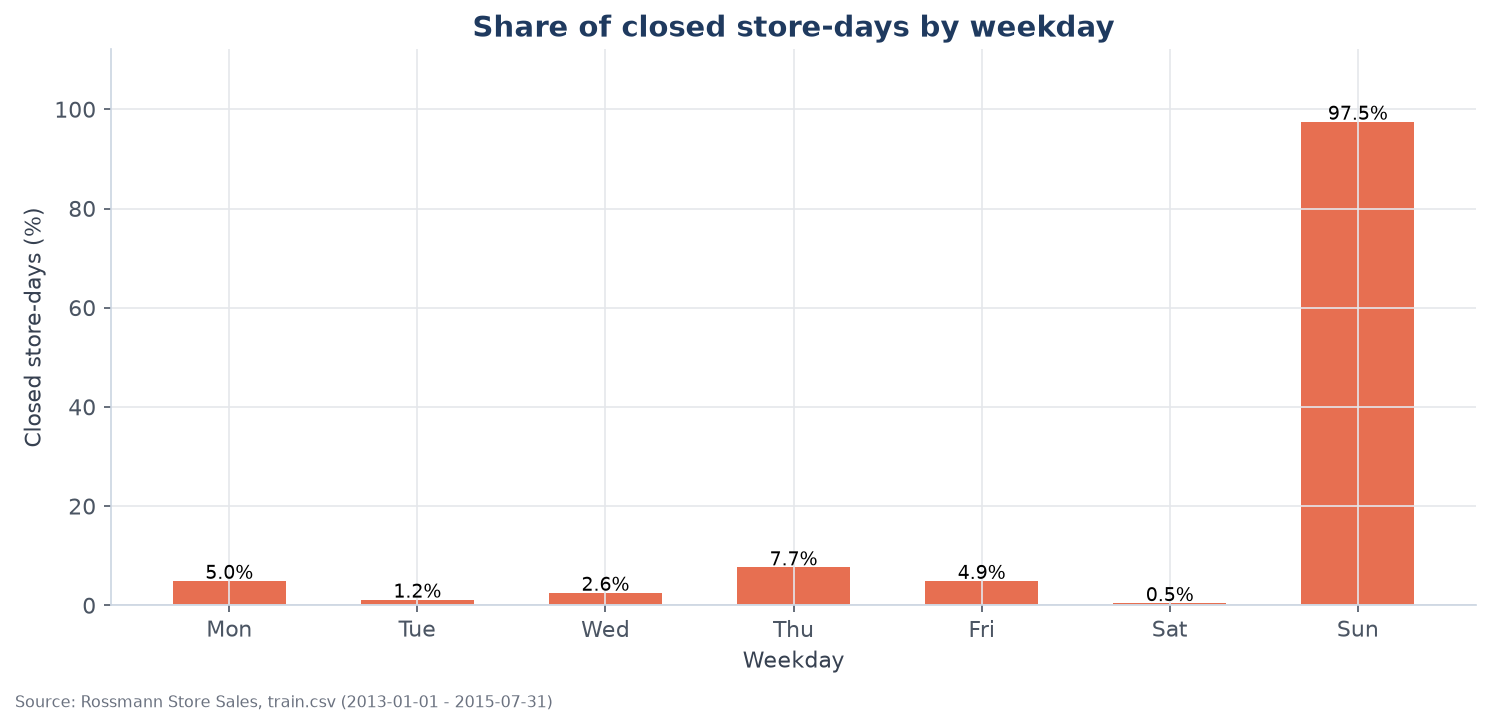

In [19]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig14_opening_pattern.png"), width=950))

**Interpretation.** 97.5% of Sundays are closed, and Sundays account for 82% of all closed store-days, while other weekdays are closed only about 3-4% of the time. This is a structural pattern, not missing data. Any model that treats a Sunday closure as "zero demand" will systematically under-forecast Monday if the lag features are not built carefully.

## 6. Statistical tests: what they do and do not prove

In [20]:
tests = pd.DataFrame([
    {"test": "Promo effect (paired across stores)", "statistic": summary["tests"]["promo_paired_t"]["statistic"],
     "p_value": summary["tests"]["promo_paired_t"]["p_value"]},
    {"test": "Weekday differences (Kruskal-Wallis)", "statistic": summary["tests"]["weekday_kruskal"]["statistic"],
     "p_value": summary["tests"]["weekday_kruskal"]["p_value"]},
    {"test": "Store type differences (Kruskal-Wallis)", "statistic": summary["tests"]["store_type_kruskal"]["statistic"],
     "p_value": summary["tests"]["store_type_kruskal"]["p_value"]},
    {"test": "Holiday differences (Kruskal-Wallis)", "statistic": summary["tests"]["holiday_kruskal"]["statistic"],
     "p_value": summary["tests"]["holiday_kruskal"]["p_value"]},
])
display(tests)
print("With hundreds of thousands of observations, tiny differences become statistically significant. Effect sizes and business relevance matter more than p-values alone.")

,test,statistic,p_value
0,Promo effect (paired across stores),74.970370,0.000000e+00
1,Weekday differences (Kruskal-Wallis),43128.115233,0.000000e+00
2,Store type differences (Kruskal-Wallis),8221.020373,0.000000e+00
3,Holiday differences (Kruskal-Wallis),74.491174,4.657540e-16


With hundreds of thousands of observations, tiny differences become statistically significant. Effect sizes and business relevance matter more than p-values alone.


## 7. Key findings

1. **Scale dispersion is the dominant fact.** Stores differ by an order of magnitude; any model needs store-level history.
2. **Weekly seasonality is strong and stable.** Monday is the peak, Saturday the trough, Sunday is mostly closed.
3. **Promotions coincide with +38.8% sales and +21.2% traffic.** The association is consistent across stores, but causality is not established.
4. **Annual seasonality exists but is estimated from only two cycles.** Summer is stronger; December is volatile.
5. **Competition distance is a weak, confounded correlate.** It belongs in the model as a control.
6. **Customers are almost collinear with sales.** They are useful only as lagged features, never as contemporaneous inputs.
7. **Volatility differs across stores.** The top decile of CV stores deserves operational attention.

These findings directly shape the feature set in notebook 05 and the model comparison in notebooks 06-08.